<center><p float="center">
  <img src="https://upload.wikimedia.org/wikipedia/commons/e/e9/4_RGB_McCombs_School_Brand_Branded.png" width="360"/>
  <img src="https://mma.prnewswire.com/media/1458111/Great_Learning_Logo.jpg?p=facebook" width="240"/>
</p></center>

<center><font size=10>Artificial Intelligence and Machine Learning</font></center>
<center><font size=6>MLS 2: Data Manipulation and Exploratory Data Analysis</font></center>

<center><p float="center">
  <img src="https://images.pexels.com/photos/29942709/pexels-photo-29942709.jpeg" width="640"/>
</p></center>

<center><font size=6>Streaming Platform Customer Churn Analysis</font></center>

# **Problem Statement**

## **Business Context**

StreamWave is a US-based, publicly listed OTT streaming platform with 40 million subscribers across North America and Western Europe. It offers three subscription tiers:

- **Basic:** \$6.99/month
- **Standard:** \$12.99/month
- **Premium:** \$18.99/month

The platform spans originals, licensed movies, live sports, and ad-supported free trials, generating approximately **\$4.2 billion in annual revenue**.

In a highly competitive market with established players like Netflix, Disney+, Amazon Prime Video, and Hulu, subscriber churn is the single largest operational challenge. The company faces a **monthly churn rate of 5.8%**, translating to roughly **2.3 million cancellations or downgrades per month**.

Acquiring a replacement subscriber costs **\$65**, compared to just **\$8–\$12** to retain an existing one. Customer lifetime value (CLV) averages **\$112**, well below the industry top-quartile benchmark of **\$145–\$160**.

Two prior retention attempts, a blanket discount and a generic email drip, both failed because they were designed without a data-driven understanding of subscriber behavior. Meanwhile, industry growth has slowed below **3%**, competitors have pivoted to retention-first strategies.

## **Objective**

Conduct a structured, first-cut, data-driven analysis to identify behavioral and pricing-related characteristics that distinguish churned subscribers from retained ones.

Specifically:
- Perform univariate analysis to understand the distribution of acquisition channels, subscription tiers, and engagement levels.
- Use bivariate and multivariate analysis to explore how acquisition channel, subscription tier, and engagement score relate to churn status individually and in combination.

The output should be directional insights and recommendations for StreamWave's marketing and retention teams to improve CLV and reduce avoidable churn.

## **Data Dictionary**

**Note:** The data extract is from 1st April 2022 to 31st March 2026.

### `subscribers.csv`

| Column | Type | Description |
|---|---|---|
| `subscriber_id` | string | Master identifier for the subscriber record. |
| `account_id` | string | Account identifier; multiple subscribers can share one account |
| `age` | int | Subscriber age in years |
| `gender` | category | Subscriber gender identity |
| `region` | category | Broad geographic region |
| `country` | category | Subscriber country |
| `signup_date` | date | Date subscriber first activated their account |
| `current_plan` | category | Active subscription tier |
| `signup_channel` | category | Acquisition channel at time of signup |
| `device_primary` | category | Primary device used for streaming |
| `household_size` | int | Number of people in subscriber's household |
| `churn_status` | binary | Whether the subscriber churned during the observation window |
| `churn_date` | date / null | Date of cancellation; null if retained |
| `price_increase_flag` | binary | Whether subscriber experienced a price hike in the last 6 months |
| `is_resub` | binary | Whether subscriber previously cancelled and reactivated |

---

### `watch_history.csv`

| Column | Type | Description |
|---|---|---|
| `session_id` | string | Unique tracking identifier for the streaming session. |
| `subscriber_id` | string | Cross-reference to the corresponding profile in the subscribers.csv dataset. |
| `session_date` | datetime | Date and time the viewing session occurred |
| `content_id` | string | Unique identifier for the content watched |
| `content_category` | category | Genre or rights category of the content |
| `content_length_minutes` | int | Total runtime of the content |
| `watch_duration_minutes` | int | Actual minutes watched in the session |
| `completion_pct` | float | Share of content watched (watch duration / content length) |
| `device_used` | category | Device used during this specific session |
| `time_of_day` | category | Time-of-day bucket when the session started |
| `engagement_score` | float | Engagement metric scaled to a 0-100 range |


---

# **Installing and Importing the Necessary Libraries**

In [ ]:
# Bootstrap autonome : installe uv si nécessaire, prépare l'environnement du projet et importe les dépendances.
import os
import shutil
import subprocess
import sys
import sysconfig
from pathlib import Path

# Trouver la racine du projet en remontant depuis le répertoire courant.
project_root = next(
    (parent for parent in [Path.cwd(), *Path.cwd().parents]
     if (parent / 'pyproject.toml').exists() and (parent / 'dataset').is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Placez MLS_DMEDA.ipynb dans le projet avec pyproject.toml et dataset/.")
os.chdir(project_root)

# Installer uv dans l'environnement utilisateur s'il n'est pas déjà disponible.
uv_path = shutil.which('uv')
if uv_path is None:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '--user', 'uv'], check=True)
    user_bin = Path(sysconfig.get_path('scripts', scheme='nt_user' if os.name == 'nt' else 'posix_user'))
    uv_path = str(user_bin / ('uv.exe' if os.name == 'nt' else 'uv'))
    if not Path(uv_path).exists():
        raise RuntimeError("uv a été installé mais son exécutable est introuvable. Redémarrez le noyau et relancez cette cellule.")

# Garantir Python 3.12 pour le noyau et synchroniser les dépendances verrouillées.
subprocess.run([uv_path, 'python', 'install', '3.12'], cwd=project_root, check=True, stdout=subprocess.DEVNULL)
venv_python = project_root / '.venv' / ('Scripts/python.exe' if os.name == 'nt' else 'bin/python')
if venv_python.exists():
    current_version = subprocess.check_output(
        [str(venv_python), '-c', 'import sys; print(f"{sys.version_info.major}.{sys.version_info.minor}")'],
        text=True,
    ).strip()
    if current_version != '3.12':
        shutil.rmtree(project_root / '.venv')
subprocess.run([uv_path, 'sync', '--python', '3.12', '--quiet'], cwd=project_root, check=True)

# Charger les paquets de l'environnement Python 3.12 dans le noyau actuel.
site_packages = project_root / '.venv' / 'Lib' / 'site-packages' if os.name == 'nt' else next(
    (project_root / '.venv' / 'lib').glob('python3.12/site-packages'), None
)
if site_packages is None or not site_packages.exists():
    raise RuntimeError("Impossible de localiser les paquets installés dans l'environnement Python 3.12.")
if str(site_packages) not in sys.path:
    sys.path.insert(0, str(site_packages))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print(f'Environnement prêt avec uv | Pandas {pd.__version__} | Matplotlib {plt.matplotlib.__version__} | Seaborn {sns.__version__}')

Cette cellule prépare automatiquement l’environnement avec `uv` et fixe le noyau du projet sur Python 3.12. Si `uv` ou Python 3.12 manque, il les installe; elle synchronise ensuite les dépendances et charge les bibliothèques dans le noyau courant.


**Prompt**:

<font size=3 color="4682B4">
Set up the analysis environment. Import all libraries needed for data manipulation and visualization

</font>

In [ ]:
# Libraries to help with reading and manipulating data
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# to restrict the float value to 3 decimal places
pd.set_option('display.float_format', lambda x: '%.3f' % x)

# **Data Overview**

### Load the data

Les fichiers CSV fournis se trouvent dans le dossier `dataset/`. La cellule de chargement ci-dessous recherche ce dossier à partir du notebook, indépendamment du répertoire courant du noyau.

**Prompt**:

<font size=3 color="4682B4">
StreamWave's data is available across two separate files covering subscriber profiles and viewing sessions. Load both of them, confirm they have loaded correctly
</font>

In [ ]:
from pathlib import Path

# Locate the provided CSV files relative to this notebook, regardless of the kernel's working directory.
notebook_dir = next(
    parent for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / 'dataset' / 'subscribers.csv').exists()
)
data_dir = notebook_dir / 'dataset'
df_subscribers = pd.read_csv(data_dir / 'subscribers.csv')
df_watch_history = pd.read_csv(data_dir / 'watch_history.csv')

# Verify shapes
print(f"df_subscribers: {df_subscribers.shape}")
print(f"df_watch_history: {df_watch_history.shape}")

df_subscribers: (10000, 15)
df_watch_history: (306935, 11)


### Check for row counts, column counts, and samples

**Prompt**:

<font size=3 color="4682B4">
Provide the row count, column count, and a representative sample of the data for each dataset.

In [ ]:
# Store both dataframes in a dictionary for iterating
dataframes = {
    "df_subscribers": df_subscribers,
    "df_watch_history": df_watch_history
}

# Display row count, column count, and first 5 rows for each
for name, df in dataframes.items():
    print(f"\n--- {name} ---")
    print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
    display(df.head())


--- df_subscribers ---
Rows: 10000, Columns: 15


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
0,SUB_000001,ACC_000001,44.000,Male,North America,CA,2022-12-15,Standard,Referral,Mobile,1.000,0,NaN,0,0
1,SUB_000002,ACC_000002,NaN,Male,Western Europe,DE,2026-01-30,Basic-Ads,Free Trial,Mobile,2.000,1,2026-02-21,1,0
2,SUB_000003,ACC_000003,32.000,Female,North America,US,2024-02-25,Premium,Paid Social,TV,4.000,0,NaN,0,0
3,SUB_000004,ACC_000004,33.000,Male,North America,US,2024-06-24,Basic-Ads,Paid Social,TV,2.000,1,2026-01-13,1,0
4,SUB_000005,ACC_000005,32.000,Undisclosed,North America,US,2025-11-28,Basic-Ads,Paid Social,TV,NaN,1,2026-02-28,0,0



--- df_watch_history ---
Rows: 306935, Columns: 11


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day,engagement_score
0,SES_00000001,SUB_000001,2025-08-13,CNT_00945,Licensed Movies,107,106,0.993,Mobile,Morning,50.348
1,SES_00000002,SUB_000001,2026-02-20,CNT_21098,Live Sports,120,71,0.599,Mobile,Evening,50.348
2,SES_00000003,SUB_000001,2025-04-22,CNT_49631,Ad-Supported Catalog,43,37,0.865,Mobile,Evening,50.348
3,SES_00000004,SUB_000001,2025-08-02,CNT_34829,Originals,50,30,0.614,Mobile,Evening,50.348
4,SES_00000005,SUB_000001,2025-04-05,CNT_23324,Ad-Supported Catalog,46,34,0.744,Mobile,Evening,50.348


### Data Quality Checks: Missing Values, Duplicates, Data Types

**Prompt**:

<font size=3 color="4682B4">
For each dataset, check for the presence of missing values, duplicate values, and data type issues. If present, highlight where they occur.

In [ ]:
# Check missing values, duplicates, and data types for each dataset
for name, df in dataframes.items():
    print(f"\n---- Data Quality Check for {name} ----")

    # Missing values as a rounded percentage
    print("Missing Values (%):\n", round(df.isnull().sum() / df.isnull().count() * 100, 3))

    # Duplicate rows count
    print(f"\nDuplicate rows: {df.duplicated().sum()}")

    # Data types
    print(f"\nData Types:\n {df.dtypes}")


---- Data Quality Check for df_subscribers ----
Missing Values (%):
 subscriber_id          0.000
account_id             0.000
age                    2.790
gender                 4.490
region                 0.000
country                0.000
signup_date            0.000
current_plan           0.000
signup_channel         0.000
device_primary         1.970
household_size        12.220
churn_status           0.000
churn_date            64.990
price_increase_flag    0.000
is_resub               0.000
dtype: float64

Duplicate rows: 0

Data Types:
 subscriber_id           object
account_id              object
age                    float64
gender                  object
region                  object
country                 object
signup_date             object
current_plan            object
signup_channel          object
device_primary          object
household_size         float64
churn_status             int64
churn_date              object
price_increase_flag      int64
is_resub     

- The `churn_date` column is missing for ~65% of rows. This is expected because a null churn date simply means the subscriber has not churned (i.e., they are still retained).
- Other missing values are smaller: `household_size` (12.22%), `gender` (4.49%), `age` (2.79%), and `device_primary` (1.97%). These missing values will not be imputed for this analysis as imputation is out of scope for this case study.
- No duplicate rows in either dataset.
- All date columns are stored as plain text and need to be converted to datetime format.

### Descriptive Statistics

**Prompt**:

<font size=3 color="4682B4">
Generate the descriptive statistics of both the datasets

In [ ]:
# Generate descriptive statistics for both datasets
for name, df in dataframes.items():
    print(f"\n--- Descriptive Statistics for {name} ---")
    display(df.describe(include='all'))


--- Descriptive Statistics for df_subscribers ---


,subscriber_id,account_id,age,gender,region,country,signup_date,current_plan,signup_channel,device_primary,household_size,churn_status,churn_date,price_increase_flag,is_resub
count,10000,10000,9721.000,9551,10000,10000,10000,10000,10000,9803,8778.000,10000.000,3501,10000.000,10000.000
unique,10000,9434,NaN,4,2,8,1448,3,6,4,NaN,NaN,366,NaN,NaN
top,SUB_009984,ACC_009212,NaN,Female,North America,US,2026-03-06,Basic-Ads,Free Trial,TV,NaN,NaN,2026-03-30,NaN,NaN
freq,1,3,NaN,4264,5996,4978,30,4846,2287,4790,NaN,NaN,35,NaN,NaN
mean,NaN,NaN,40.184,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.416,0.350,NaN,0.218,0.062
std,NaN,NaN,13.907,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.316,0.477,NaN,0.413,0.241
min,NaN,NaN,18.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,0.000,NaN,0.000,0.000
25%,NaN,NaN,29.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000,0.000,NaN,0.000,0.000
50%,NaN,NaN,39.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000,0.000,NaN,0.000,0.000
75%,NaN,NaN,51.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000,1.000,NaN,0.000,0.000



--- Descriptive Statistics for df_watch_history ---


,session_id,subscriber_id,session_date,content_id,content_category,content_length_minutes,watch_duration_minutes,completion_pct,device_used,time_of_day,engagement_score
count,306935,306935,306935,306935,306935,306935.000,306935.000,306935.000,301907,306935,306935.000
unique,306935,9865,366,49896,5,NaN,NaN,NaN,4,4,NaN
top,SES_00306935,SUB_003615,2026-02-28,CNT_20822,Licensed Movies,NaN,NaN,NaN,TV,Evening,NaN
freq,1,100,986,18,96917,NaN,NaN,NaN,148854,153458,NaN
mean,NaN,NaN,NaN,NaN,NaN,74.577,48.861,0.662,NaN,NaN,52.425
std,NaN,NaN,NaN,NaN,NaN,38.115,30.160,0.198,NaN,NaN,19.923
min,NaN,NaN,NaN,NaN,NaN,15.000,0.000,0.050,NaN,NaN,0.000
25%,NaN,NaN,NaN,NaN,NaN,45.000,26.000,0.536,NaN,NaN,36.922
50%,NaN,NaN,NaN,NaN,NaN,60.000,41.000,0.693,NaN,NaN,52.913
75%,NaN,NaN,NaN,NaN,NaN,105.000,68.000,0.816,NaN,NaN,70.219


**Subscribers (10,000 records)**
- Age ranges 18-70 (mean ~40, std ~14). North America dominates (5,996 of 10,000); US is the top country.
- Basic-Ads is the most common plan (~4,846). Free Trial is the top acquisition channel (2,287).
- TV is the primary device (4,790 of 9,803 with data). Average household size is ~2.4.
- Churn rate is 35%. Only 6.2% are re-subscribers. 21.8% experienced a price increase.

**Watch History (306,935 sessions)**
- 9,865 unique subscribers have watch activity, meaning ~135 subscribers have no sessions at all.
  - These 135 subscribers will be excluded from further analysis, as the reason for having no recorded sessions is unknown, whether due to lack of engagement or missing/untracked activity.
- Licensed Movies dominate content (96,917 sessions). Evening is peak viewing time (153,458 sessions).
- Average content length is ~75 min; average watch duration is ~49 min (about 66% completion on average).
- Engagement score ranges from 0 to 98.3.

# **Data Preprocessing**

## Parse Data Types

Date columns are currently stored as plain text, which prevents any time-based computations. Let's convert all date-like columns across both datasets to proper `datetime` format.

**Prompt**:

<font size=3 color="4682B4">
Parse and standardize all date columns to a consistent datetime format across both the datasets.

In [ ]:
# Convert date columns in df_subscribers
# errors='coerce' sets invalid entries to NaT
df_subscribers['signup_date'] = pd.to_datetime(df_subscribers['signup_date'], errors='coerce')
df_subscribers['churn_date'] = pd.to_datetime(df_subscribers['churn_date'], errors='coerce')

# Convert date columns in df_watch_history
df_watch_history['session_date'] = pd.to_datetime(df_watch_history['session_date'], errors='coerce')

# Verify converted data types
print("df_subscribers date columns:")
print(df_subscribers[['signup_date', 'churn_date']].dtypes)
print("\ndf_watch_history date column:")
print(df_watch_history['session_date'].dtypes)

df_subscribers date columns:
signup_date    datetime64[ns]
churn_date     datetime64[ns]
dtype: object

df_watch_history date column:
datetime64[ns]


- All date columns now show as `datetime64[ns]`.

# **Exploratory Data Analysis**

## **Univariate Analysis**

A univariate plot is worth showing if it surfaces a decision, exposes a data quality issue, or reveals an unexpected distribution. We focus on three: subscriber distribution across acquisition channels, pricing tiers, and engagement score distribution.

### Q1: Which acquisition channels are driving the highest volume of our subscriber base?

A subscriber's acquisition channel often dictates their initial intent and churn likelihood. Visualizing the distribution across signup methods lets us identify which channels feed the platform the most, and later investigate if high-volume channels bring in low-intent subscribers.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of subscribers across different signup channels using a bar chart, sorted by the highest volume to the lowest.

**Distribution of Subscribers Across Signup Channels**

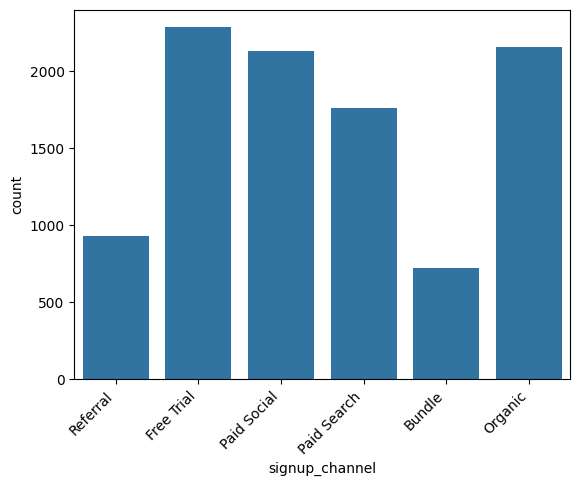

In [ ]:
# Count plot of subscribers by signup channel, sorted by volume
sns.countplot(data=df_subscribers, x='signup_channel')
plt.xticks(rotation=45, ha='right')
plt.show()

- Free Trial is the largest acquisition channel (\~2,300 subscribers), followed by Organic (\~2,160) and Paid Social (\~2,130).
- Referral (\~930) and Bundle (\~725) generate the lowest signup volume.

### Q2: What is the distribution of subscribers across our pricing tiers?

Understanding how subscribers distribute across pricing plans reveals the baseline revenue mix and whether acquisition is driving users toward Premium plans or concentrating them at lower, potentially higher-churn tiers.

**Prompt**:

<font size=3 color="4682B4">Visualize the total number of subscribers across each current subscription plan using a bar chart.

**Distribution of Subscribers Across Current Plans**

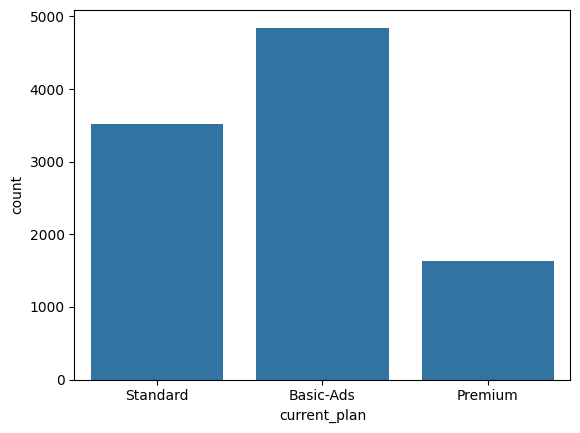

In [ ]:
# Count plot of subscribers by subscription plan
sns.countplot(data=df_subscribers, x='current_plan')
plt.show()

- The majority of subscribers are on the Basic-Ads plan.
- As plan pricing increases, the number of subscribers decreases, which is expected.

### Q3: How are subscriber engagement levels distributed across the user base?

An active subscription does not guarantee actual platform usage. The engagement score distribution reveals whether the bulk of the user base is highly engaged, casually watching, or acting as "zombie" accounts at high risk of passive churn.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of the engagement score using a histogram to understand the overall activity levels of our subscriber base.

Since a subscriber may have multiple watch sessions, we aggregate the engagement score by taking the mean across all sessions to get a single subscriber-level metric.

**Groupby Function**<br>
Pandas *GroupBy* is a powerful and versatile function in Python. It allows you to split your data into separate groups to perform computations for better analysis.*GroupBy* allows us to group our data based on different features and get a more accurate idea about your data.

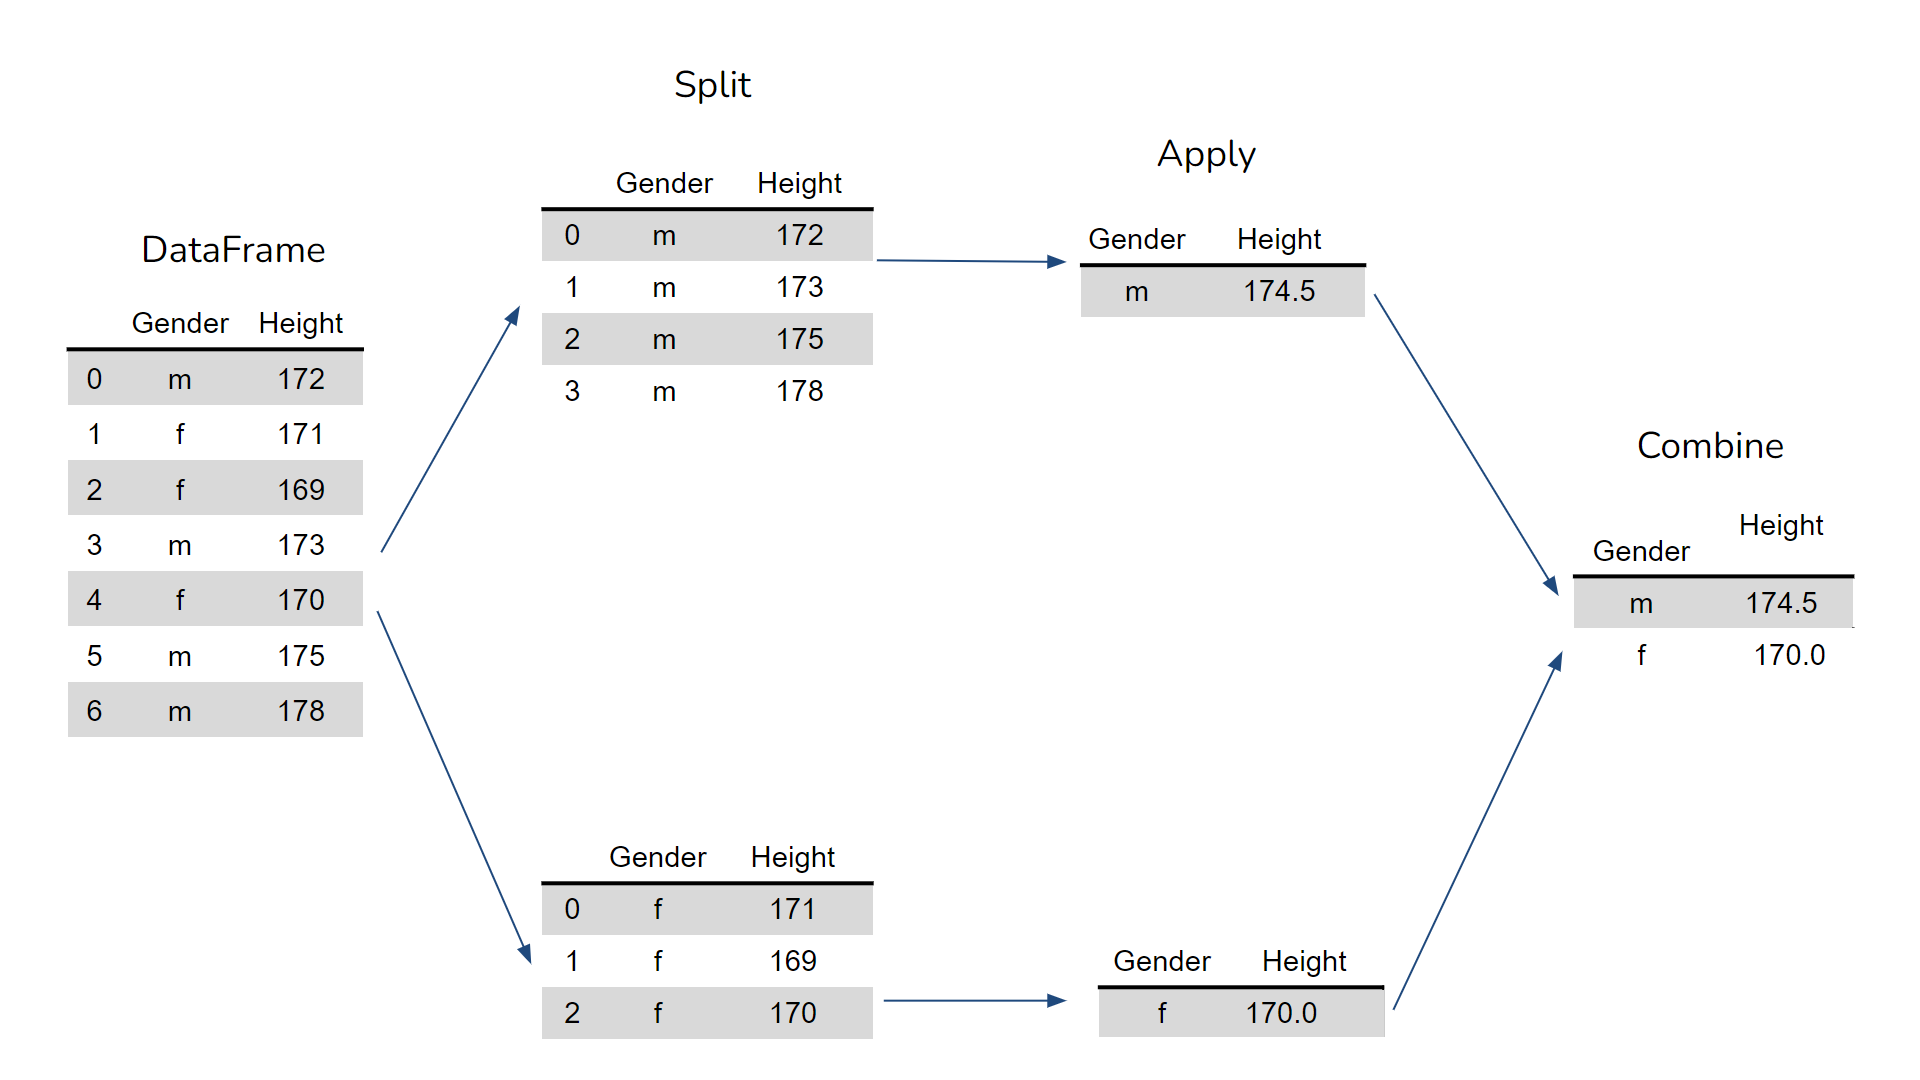

In [ ]:
# Summarize engagement score per subscriber (mean across all sessions)
subscriber_engagement = df_watch_history.groupby('subscriber_id')['engagement_score'].mean().reset_index()

Once we have the subscriber engagement information, we merge it with the subscriber details.

**Merge/Join / Concatenation**<br>
Pandas provide various facilities for easily combining together Series or DataFrame with various kinds of set logic for the indexes and relational algebra functionality in the case of join / merge-type operations.<br>

**Left Join**: Returns all records from the left table, and the matched records from the right table<br>

<img src= "https://i.ibb.co/72ngdJ1/left.png" >


In [ ]:
# Merge subscriber-level engagement into the subscribers dataframe
merged_df = pd.merge(df_subscribers, subscriber_engagement, on='subscriber_id', how='left')

**Engagement Score Distribution**

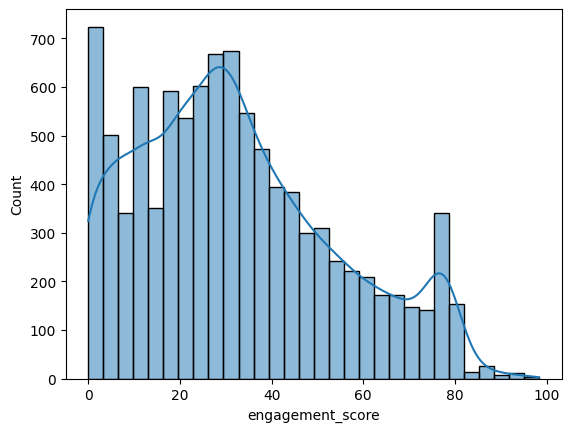

In [ ]:
# Histogram of engagement scores with KDE overlay
sns.histplot(merged_df['engagement_score'], bins=30, kde=True)
plt.show()

- The distribution is right-skewed; most subscribers have low-to-middle engagement (scores between 15 and 45).
- A smaller secondary peak around 75-80 indicates a concentrated segment of highly active users.

## **Bivariate Analysis**

Bivariate analysis connects our baseline metrics to uncover individual drivers behind subscriber behavior. We focus on three relationships: acquisition channel vs. engagement, subscription plan vs. engagement, and engagement vs. churn.

### Q1: Is there a measurable difference in engagement levels based on acquisition channel?

Our univariate analysis showed that the overall user base skews toward low engagement and Free Trial is the highest-volume channel. We now cross-reference engagement scores with signup channels to check if specific channels are driving the low engagement.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of engagement scores across different signup channels using a box plot to see if certain channels bring in more highly engaged users.

**Distribution of Engagement Scores by Signup Channel**

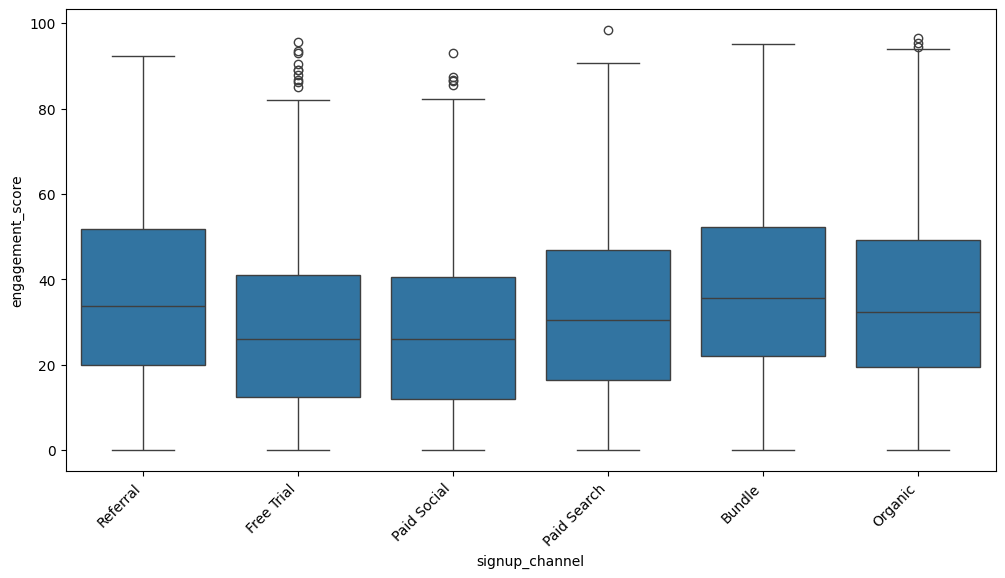

In [ ]:
# Boxplot of engagement scores by signup channel
plt.figure(figsize=(12, 6))
sns.boxplot(x='signup_channel', y='engagement_score', data=merged_df)
plt.xticks(rotation=45, ha='right')
plt.show()

- Free Trial and Paid Social bring in the highest volume but have the lowest median engagement scores.
- Referral and Bundle bring fewer subscribers but show the highest median engagement.

### Q2: Is there a measurable difference in engagement levels based on subscription plan?

We need to check if the amount subscribers pay matches how much they use the platform. Comparing engagement scores across plans reveals whether higher-tier users are more active or engaging at similar levels as Basic-Ads users.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of engagement scores across different subscription plans using a box plot to see how user engagement levels vary between different subscription tiers.

**Distribution of Engagement Scores by Subscription Plan**

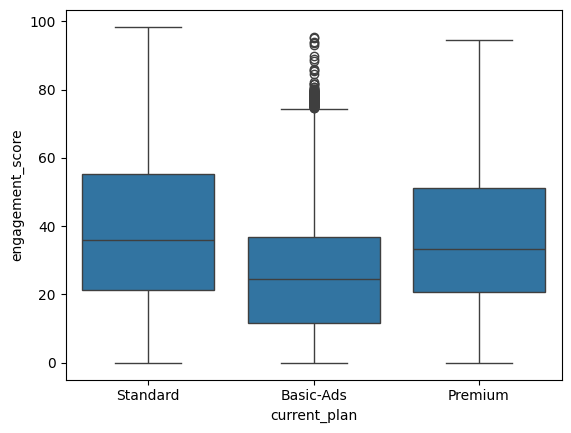

In [ ]:
# Boxplot of engagement scores by subscription plan
sns.boxplot(data=merged_df, x='current_plan', y='engagement_score')
plt.show()

- Basic-Ads has the lowest median engagement and a narrower interquartile range. A cluster of high-engagement outliers is visible for this plan.
- Standard records the highest median engagement, slightly above Premium.
- Higher pricing does not strictly mean higher engagement.

### Q3: Is lack of engagement a behavioral divider between retained and churned users?

A high percentage of users have low engagement, especially from high-volume channels like Free Trial. The next step is to check whether low engagement is the primary behavioral driver of churn by comparing engagement distributions between retained and churned subscribers.

**Prompt**:

<font size=3 color="4682B4">Visualize the distribution of the engagement score split by churn status using a filled KDE plot to compare the behavioral patterns of retained versus churned subscribers.

**Engagement Score by Churn Status**

In [ ]:
# Create a readable churn label column
merged_df['churn_label'] = merged_df['churn_status'].map({0: 'Retained', 1: 'Churned'})

`map()` replaces each value with its corresponding label from the dictionary, converting `0` to `Retained` and `1` to `Churned`.

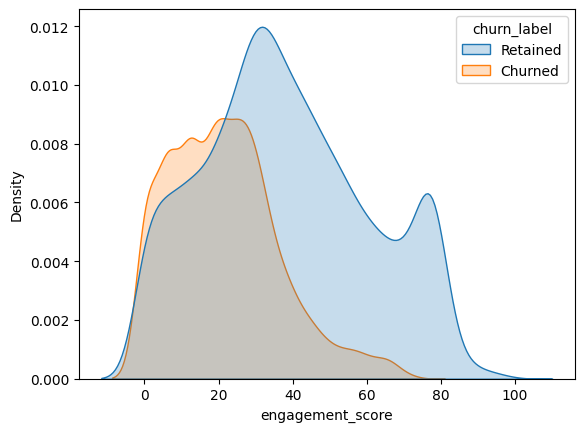

In [ ]:
# KDE plot of engagement score split by churn status
# Custom palette used here to clearly distinguish retained (green) vs churned (red)
sns.kdeplot(data=merged_df, x='engagement_score', hue='churn_label',fill=True)
plt.show()

- Churned subscribers are concentrated in the lower engagement range.
- Retained users dominate higher engagement levels, suggesting a threshold (around 40-60) where churn risk drops significantly.
- The retained group has a secondary peak around 75-80 with almost no churned users in that region, confirming that highly active subscribers carry virtually zero churn risk.

## **Multivariate Analysis**

In bivariate analysis, we checked signup channel vs. engagement, plan vs. engagement, and engagement vs. churn separately. Multivariate analysis tests whether these results hold when all three variables are considered together. For example: does engagement affect churn the same way for every signup channel? For every subscription plan?

### Q1: Does a user's engagement level override the churn risk of their signup channel?

To visualize this, we translate the continuous engagement score (0–100) into actionable behavioral segments using `pd.cut`.

- `pd.cut` assigns users to predefined engagement score ranges rather than creating groups of equal size.
- We define 5 engagement tiers, from **'Checked Out'** to **'Obsessed'**, based on specific score thresholds. This makes the segments easier to interpret and apply consistently across the analysis.

We then create a heatmap to see if moving a user into a higher engagement tier can neutralize the churn risk associated with their acquisition channel.

**Prompt**:

<font size=3 color="4682B4"> Divide the engagement score into 5 equal-sized quantiles (Checked Out, Slowing Down, Casual, Regular, Obsessed). Name the resulting categorical column eng_tier in a dataframe named merged_df.

In [ ]:
# Define engagement tier labels (lowest to highest)
eng_labels = ['Checked Out', 'Slowing Down', 'Casual', 'Regular', 'Obsessed']

# The bin values correspond to the observed engagement-score cutoffs at selected percentiles, dividing subscribers into five engagement tiers from lowest to highest engagement.
eng_bins = [0, 12, 25, 35, 51, 98]

# Assign subscribers to engagement tiers using the predefined ranges
merged_df['eng_tier'] = pd.cut(
    merged_df['engagement_score'],
    bins=eng_bins,
    labels=eng_labels,
    include_lowest=True
)

print(merged_df['eng_tier'].value_counts())

eng_tier
Checked Out     1973
Slowing Down    1973
Casual          1973
Regular         1973
Obsessed        1972
NaN              136
Name: count, dtype: int64


**Prompt**:

<font size=3 color="4682B4"> Create a heatmap visualizing the churn rate by signup channel and the engagement tiers to see if high engagement lowers churn universally.

Heatmaps are commonly used to visualize correlations between numerical variables. However, they are equally effective for visualizing any matrix of values. Here we use one to display churn rates across two categorical dimensions (channel x engagement tier).

**Sign-up Channel x Engagement Tier x Churn**

- `unstack()` pivots the engagement tiers from rows into separate columns, making it easier to compare churn rates across signup channels.

In [ ]:
# Pivot table: churn rate by signup channel and engagement tier
channel_eng_churn = merged_df.groupby(
    ['signup_channel', 'eng_tier']
)['churn_status'].mean().unstack() * 100

/tmp/ipykernel_1180/2802784432.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  channel_eng_churn = merged_df.groupby(


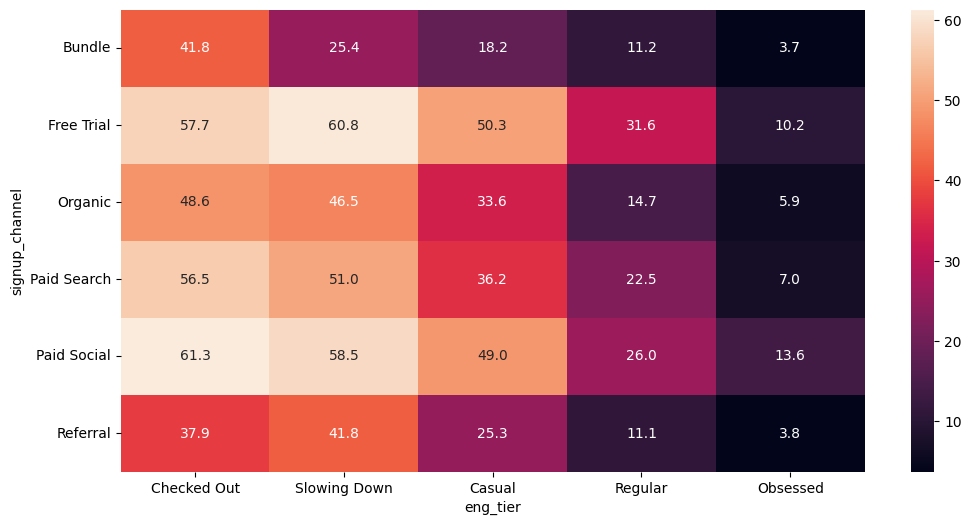

In [ ]:
# Heatmap of churn rates
plt.figure(figsize=(12, 6))
sns.heatmap(channel_eng_churn, annot=True, fmt='.1f')
plt.yticks(rotation=0)
plt.show()

- Higher engagement corresponds to lower churn across every channel.
- Free Trial and Paid Social subscribers are more prone to churn than others.
- Engagement helps but does not completely override channel risk: "Obsessed" subscribers from Free Trial or Paid Social still churn at nearly 3x the rate of the same tier from Bundle or Referral.

### Q2: To what extent does high engagement shield the platform against the friction of ad-supported or premium-priced tiers?

We need to know if deep engagement acts as a shield against churn even for users on the cheapest or ad-heavy tiers. Cross-tabulating subscription plan with engagement tiers reveals whether moving a user up one engagement bracket can save their account.

**Prompt**:

<font size=3 color="4682B4">Create a heatmap visualizing the churn rate by current subscription plan and custom engagement score tiers (Checked Out, Slowing Down, Casual, Regular, Obsessed).

**Subscription Plan x Engagement Tier x Churn**

In [ ]:
# Pivot table: churn rate by subscription plan and engagement tier
plan_eng_churn = merged_df.groupby(
    ['current_plan', 'eng_tier']
)['churn_status'].mean().unstack() * 100

/tmp/ipykernel_1180/2572222609.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  plan_eng_churn = merged_df.groupby(


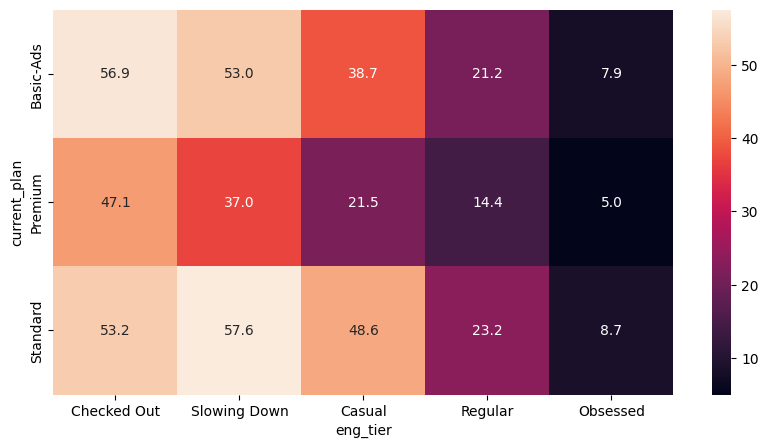

In [ ]:
# Heatmap of churn rates
plt.figure(figsize=(10, 5))
sns.heatmap(plan_eng_churn, annot=True, fmt='.1f')
plt.show()

- Higher engagement corresponds to lower churn across all plans.
- Premium users are inherently less likely to churn than Basic-Ads users at every engagement level.
- Standard plan shows an unusual pattern: churn peaks in "Slowing Down" (~58%), not "Checked Out". This is higher than the ~42% churn rate of zero-activation subscribers, suggesting early disengagement may be a stronger churn signal than having no activity at all.

# **Business Insights and Recommendations**

## Business Insights

- **Acquisition Channels:** Free Trial and Paid Social generate the highest volume but have the lowest engagement and highest churn risk. Referral and Bundle yield fewer but more engaged, retained subscribers.
- **Standard Plan Anomaly:** Churn peaks in the "Slowing Down" tier rather than "Checked Out", suggesting users actively cancel as they notice declining usage.
- **Pricing and Loyalty:** Lower cost does not mean higher loyalty. Basic-Ads has the highest churn proportion, while Premium maintains the strongest retention (~22% churn).

## Recommendations

**For the Marketing Team:**

- **Redesign Free Trial Onboarding:** Keep spending on high-volume channels but redesign the onboarding flow so trial users quickly find relevant content and start watching immediately.
- **Scale Referral and Bundle Programs:** Allocate more acquisition budget to these channels since they naturally bring in higher-engagement, longer-retained subscribers.
- **Target Premium Upsells:** Focus upgrade campaigns on active Basic-Ads and Standard users, as Premium members are the least likely to churn.

**For the Retention Team:**

- **Early Intervention Alerts:** Set up automated alerts for subscribers whose engagement drops from "Regular" to "Slowing Down" levels. Reach out with targeted content recommendations before they disengage completely.
- **Fix Zero-Activation Onboarding:** Redesign the signup experience to ensure new users watch their first video immediately after account creation.

<font size=6 color="#4682B4" size=6>Power Ahead!</font>